# Fair-lending disparity testing: selection rates, the four-fifths rule, parity, equalized odds and calibration within groups


**Question:** Do the approval rates of Delaware in 2018 differ by race, ethnicity, sex and age more than chance and the four-fifths benchmark allow, and which fairness measures can be computed at all when the data hold no outcome?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 05 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- compute the selection (approval) rate of each group from decisions, and from them the parity difference, the adverse impact ratio and the four-fifths flag, on exact counts;
- test a rate gap with the two-proportion z test and Fisher's exact test, and say why a very small p-value on a very large sample does not measure how large the disparity is;
- state the legal frame honestly: the four-fifths rule is an employment benchmark used by analogy, Regulation B as amended in 2026 says the effects test does not apply under the ECOA, the Fair Housing Act is a separate statute, and gross HMDA rate disparities are indicators only;
- compute the outcome-based metrics (equal opportunity, equalized odds, calibration and AUC within groups) on planted data, and see why they cannot run on HMDA, which has no outcome;
- read the committed HMDA comparison of Delaware 2018 and 2019 (case C21) and the committed Taiwan fairness battery (case C20), and rebuild their rows with the engine.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the packages and print their versions
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import inference, metrics, plants
from riskvalidation.fairness.metrics import SelectionRate
from riskvalidation.validation import fairness as vf

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
YN = {True: "yes", False: "no"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

- **The engine's planted-bias generators** (`riskvalidation.fairness.plants`): a logistic portfolio with a binary protected group, a decision and an outcome, and one planted bias at a time with the truth known exactly. `ThresholdBiasPlant` approves the protected group at a lower cut-off by a `gap` in log-odds; `LabelNoiseBiasPlant` flips a share of the protected group's observed outcomes although the model treats both groups alike. Synthetic, from a seed, no licence class.
- **The committed HMDA comparison of Delaware, 2018 to 2019** (`data/derived/C21/pair-2018-19.json`; owner: this repository). HMDA is the Home Mortgage Disclosure Act data published by the FFIEC and the CFPB (class mirror-allowed; the licence sentence of the data is UNVERIFIED, so the document says so). It holds the number of applications and approvals per group for race, ethnicity, sex and age (loans originated or approved, action taken 1 and 2, against denied, 3), the tests the pipeline ran and a block of legal statements. **HMDA has no outcome** (no default, no repayment) and withholds the credit score, so only the selection-rate tests can run on it.
- **The committed Taiwan fairness battery of case C20** (`data/derived/C20/perturbation-grid.json`; derived from the UCI Taiwan credit-card data, CC BY 4.0): twelve engine rows, four tests by three attributes (sex, marital status and age band) on the model's PD at a fixed cut-off. The first cell opens both documents.

In [2]:
# Open both committed documents and print the engine that baked each one
hmda_path = ROOT / "data" / "derived" / "C21" / "pair-2018-19.json"
taiwan_path = ROOT / "data" / "derived" / "C20" / "perturbation-grid.json"
hmda = json.loads(hmda_path.read_text(encoding="utf-8"))
taiwan = json.loads(taiwan_path.read_text(encoding="utf-8"))
for label, doc in (("C21 pair-2018-19", hmda), ("C20 perturbation-grid", taiwan)):
    version = doc["provenance"]["riskvalidation_version"]
    print(f"{label:22s} baked with riskvalidation {version} | test rows {len(doc['tests'])}")
scope = hmda["outputs"]["scope"]
print("rows used to fit and to confirm:", scope["rows_fit"], scope["rows_confirm"], "|", scope["state"])
print("legal label of the document:", hmda["outputs"]["legal"]["label"]["en"])

C21 pair-2018-19       baked with riskvalidation 1.0.1 | test rows 95
C20 perturbation-grid  baked with riskvalidation 1.0.1 | test rows 16
rows used to fit and to confirm: 36515 41834 | DE
legal label of the document: no legal claim


## Method

### Step 1: selection rates

For a favourable decision $d_i \in \{0, 1\}$ (here: approved) and a group label $g_i$, the selection rate of group $g$ is $r_g = x_g / n_g$, with $x_g$ the favourable count and $n_g$ the size. The engine works on the **counts**, in exact integer arithmetic, and rounds once when it produces a float. The committed document stores the counts per group, so the next cell rebuilds a decision vector and a group vector with exactly those counts (this is the aggregate, not the 31,000 individual applications) and calls the engine's `group_selection_rates`. The rates must equal the committed ones.

In [3]:
# Rebuild decisions and groups from the committed counts of the race attribute and compute the selection rates
def arrays_of(attribute):
    groups = attribute["groups"]
    decision = np.concatenate([np.repeat([1, 0], [g["n_approved"], g["n_denied"]]) for g in groups])
    group = np.concatenate([np.repeat(g["group"], g["n"]) for g in groups])
    return decision, group


race = hmda["outputs"]["attributes"][0]
decision, group = arrays_of(race)
rates = metrics.group_selection_rates(decision, group)
print(race["field"], "| reference group:", race["reference_group"], "| rows:", len(decision))
for g in race["groups"]:
    r = rates[g["group"]]
    print(f"{g['group']:44s} n {r.n:6d} approved {r.favourable:6d} rate {r.rate:.4f}", end=" ")
    print(f"| committed {g['selection_rate']:.4f}")

derived_race | reference group: White | rows: 31342
American Indian or Alaska Native             n    139 approved     71 rate 0.5108 | committed 0.5108
Asian                                        n   1359 approved   1037 rate 0.7631 | committed 0.7631
Black or African American                    n   5370 approved   3315 rate 0.6173 | committed 0.6173
Native Hawaiian or Other Pacific Islander    n     86 approved     50 rate 0.5814 | committed 0.5814
White                                        n  24293 approved  18839 rate 0.7755 | committed 0.7755
2 or more minority races                     n     95 approved     47 rate 0.4947 | committed 0.4947


### Step 2: parity, the adverse impact ratio and the four-fifths rule

With a reference group $h$ (the dossier's choice for race is the largest group, White):

$$\text{parity difference: } r_g - r_h, \qquad \text{adverse impact ratio: } \mathrm{AIR}_g = \frac{r_g}{r_h}.$$

The **demographic parity** test reports the largest absolute difference against the reference and is green up to a tolerance of 0.05 (a convention), amber above, never red. The four-fifths rule of the US employment guidelines (29 CFR 1607.4(D)) compares each group with the **highest-rate** group $t$ (not necessarily the reference) and flags a group whose rate is less than four fifths of it:

$$\text{flag}_g \iff 5\,x_g\,n_t < 4\,x_t\,n_g .$$

Both rules are decided on the integers, never on a float that could miss the boundary by one unit in the last place: 60 of 100 against 75 of 100 has a float ratio of $0.7999999999999999$ and an exact ratio of $4/5$, which is **not** flagged. **The four-fifths rule is an employment benchmark used by analogy; it is not a credit-law threshold**, and the engine's result says so in a field of its own. The next cell shows the boundary, then computes the parity differences, the ratios and the flags for the race groups.

In [4]:
# The boundary case 60/100 against 75/100, then parity differences, ratios and four-fifths flags
edge_decision = np.r_[np.ones(60), np.zeros(40), np.ones(75), np.zeros(25)].astype(int)
edge_group = np.r_[np.repeat("A", 100), np.repeat("B", 100)]
edge = metrics.group_selection_rates(edge_decision, edge_group)
edge_flag = metrics.four_fifths_flag(edge).flag["A"]
print(
    "60/100 against 75/100 | float ratio",
    (60 / 100) / (75 / 100),
    "| flagged by the engine",
    YN[bool(edge_flag)],
)
reference = race["reference_group"]
parity = metrics.demographic_parity_difference(rates, reference)
air = metrics.adverse_impact_ratio(rates, reference)
four_fifths = metrics.four_fifths_flag(rates)
label = four_fifths.label
print("highest-rate group:", four_fifths.highest_rate_group, "| benchmark label:", label, end=" ")
print("| is a credit-law threshold:", YN[four_fifths.is_credit_law_threshold])
for g in race["groups"]:
    name = g["group"]
    print(
        f"{name:44s} difference {parity[name]:+.4f} | AIR {air[name]:.4f} | flag {YN[four_fifths.flag[name]]}"
    )

60/100 against 75/100 | float ratio 0.7999999999999999 | flagged by the engine no
highest-rate group: White | benchmark label: employment benchmark | is a credit-law threshold: no
American Indian or Alaska Native             difference -0.2647 | AIR 0.6587 | flag yes
Asian                                        difference -0.0124 | AIR 0.9840 | flag no
Black or African American                    difference -0.1582 | AIR 0.7960 | flag yes
Native Hawaiian or Other Pacific Islander    difference -0.1941 | AIR 0.7497 | flag yes
White                                        difference +0.0000 | AIR 1.0000 | flag no
2 or more minority races                     difference -0.2808 | AIR 0.6380 | flag yes


The flags are a list of True and False, and what they mean is clearer against the rates themselves. The next cell draws
the approval rate of each race group, colours the groups the four-fifths rule flags in red, and marks the line at 80% of
the highest rate.

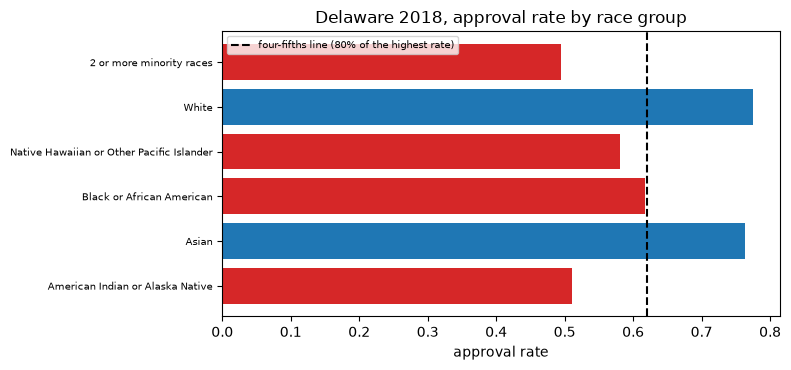

In [5]:
# Selection rates of the race groups against the four-fifths line
names = [g["group"] for g in race["groups"]]
colors = ["tab:red" if four_fifths.flag[n] else "tab:blue" for n in names]
line = 0.8 * rates[four_fifths.highest_rate_group].rate
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(names, [rates[n].rate for n in names], color=colors)
ax.axvline(line, color="black", linestyle="--", label="four-fifths line (80% of the highest rate)")
ax.set_xlabel("approval rate")
ax.set_title("Delaware 2018, approval rate by race group")
ax.tick_params(axis="y", labelsize=7)
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

The dashed line sits at 0.6204, four fifths of the White rate of 0.7755. The American Indian (0.5108), Native Hawaiian
(0.5814) and two-or-more-races (0.4947) groups lie well below it, and the Black group (0.6173) falls under it by a
hair, which is why its ratio of 0.7960 is below 0.8. The Asian group (0.7631) is not flagged. The rule is an
employment benchmark used by analogy, and it ignores how many applications stand behind each bar: 139 for the smallest
group, 24,293 for White.

The engine's tests wrap these functions into `TestResult` rows with a light. The next cell rebuilds the rates of all four attributes of the document (race, ethnicity, sex and age), calls the engine's `demographic_parity` and `adverse_impact` tests and compares the metric and the light with the committed row.

In [6]:
# For each attribute: rebuild the rates from the committed counts and call the two engine tests
committed = {(t["test_id"], t["segment"]): t for t in hmda["tests"]}
print(f"{'attribute':22s} {'groups':>7s} {'parity gap':>16s} {'light':>7s} {'AIR min':>8s} {'light':>7s}")
for attribute in hmda["outputs"]["attributes"]:
    dec, grp = arrays_of(attribute)
    r = metrics.group_selection_rates(dec, grp)
    dp = vf.demographic_parity("hmda", r, attribute["reference_group"])
    ai = vf.adverse_impact("hmda", r, attribute["reference_group"])
    old = committed[("fair.demographic_parity", attribute["field"])]
    print(f"{attribute['field']:22s} {len(r):7d} {dp.metric:16.4f} {LIGHT[dp.light.value]:>7s}", end=" ")
    print(
        f"{ai.metric:8.4f} {LIGHT[ai.light.value]:>7s} | committed {old['metric']:.4f} {LIGHT[old['light']]}"
    )

attribute               groups       parity gap   light  AIR min   light
derived_race                 6           0.2808   amber   0.6380   amber | committed 0.2808 amber
derived_ethnicity            2           0.0881   amber   0.8829   green | committed 0.0881 amber
derived_sex                  2           0.0019   green   0.9974   green | committed 0.0019 green
applicant_age                7           0.0933   amber   0.8082   green | committed 0.0933 amber
applicant_age_above_62       2           0.0258   green   0.9653   green | committed 0.0258 green


### Step 3: is a gap more than chance? The z test and Fisher's exact test

A difference of rates can be tested. For group 1 with $x_1$ of $n_1$ and group 2 with $x_2$ of $n_2$, the pooled two-proportion z statistic and its two-sided p-value are

$$z = \frac{x_1/n_1 - x_2/n_2}{\sqrt{\hat{p}(1-\hat{p})\,(1/n_1 + 1/n_2)}}, \quad \hat{p} = \frac{x_1 + x_2}{n_1 + n_2}, \qquad p = 2\bigl(1 - \Phi(|z|)\bigr),$$

and Fisher's exact test uses the hypergeometric law on the $2 \times 2$ table (the engine reports the sample odds ratio). The light is red below 0.01, amber below 0.05. A p-value answers "is the gap compatible with chance?", **not** "is the gap large": with 24,293 applications in the reference group a gap of a few points is far from chance. The next cell tests every group against the reference, rebuilds the committed rows and compares.

In [7]:
# Test every race group against the reference with the z test and Fisher's test
ref = rates[reference]
contrasts = {}
print(f"{'group':44s} {'z':>8s} {'p z':>9s} {'p Fisher':>9s} {'odds ratio':>14s} light")
for g in race["groups"]:
    if g["group"] == reference:
        continue
    s = rates[g["group"]]
    z = inference.two_proportion_z_test(s.favourable, s.n, ref.favourable, ref.n)
    f = inference.fisher_exact_test(s.favourable, s.n, ref.favourable, ref.n)
    row = vf.two_proportion_z("hmda", s.favourable, s.n, ref.favourable, ref.n)
    contrasts[g["group"]] = {"p_z": z.p_value, "ratio": f.odds_ratio}
    print(
        f"{g['group']:44s} {z.statistic:8.3f} {z.p_value:9.2e} {f.p_value:9.2e} {f.odds_ratio:14.4f}", end=" "
    )
    print(LIGHT[row.light.value])

group                                               z       p z  p Fisher     odds ratio light
American Indian or Alaska Native               -7.440  1.01e-13  1.21e-11         0.3023 red
Asian                                          -1.068  2.86e-01  2.86e-01         0.9324 green
Black or African American                     -24.124 1.40e-128 3.00e-120         0.4670 red
Native Hawaiian or Other Pacific Islander      -4.302  1.70e-05  7.36e-05         0.4021 red
2 or more minority races                       -6.534  6.40e-11  3.03e-09         0.2835 red


A p-value and an effect size answer different questions, and the two are easiest to tell apart side by side. The next
cell draws, for each group, the odds ratio of its approval against the reference group and the negative logarithm of
the p-value of the z test, with the 0.05 line.

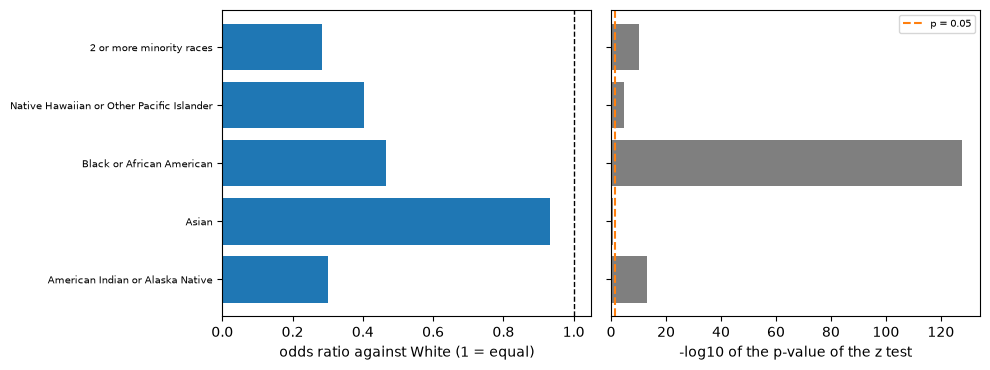

In [8]:
# Odds ratio and p-value of each race group against the reference group
names = list(contrasts)
ratios = [contrasts[n]["ratio"] for n in names]
neg_log_p = [-np.log10(contrasts[n]["p_z"]) for n in names]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
left.barh(names, ratios, color="tab:blue")
left.axvline(1.0, color="black", linestyle="--", linewidth=1)
left.set_xlabel("odds ratio against White (1 = equal)")
left.tick_params(axis="y", labelsize=7)
right.barh(names, neg_log_p, color="tab:gray")
right.axvline(-np.log10(0.05), color="tab:orange", linestyle="--", label="p = 0.05")
right.set_xlabel("-log10 of the p-value of the z test")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

The left panel is the size: the Black group has an odds ratio of 0.4670 and the American Indian group 0.3023, the latter
the larger gap. The right panel is the evidence: the Black group reaches 1.40e-128 from thousands of applications, while
the American Indian group reaches only 1.01e-13 from 139, and the Asian group (odds ratio 0.9324, p = 0.2857) is
compatible with chance. A tiny p-value therefore tracks the number of applications as much as the gap, which is why the
odds ratio is read beside it.

### Step 4: the legal frame, as the committed document states it

The document carries the legal statements the pipeline read from primary sources, so that no number in it is read as more than it is. The next cell prints them: the label of the whole document, the sentence of Regulation B as amended on 2026-04-22 (12 CFR 1002.6(a), 91 FR 21668), the statement of the Interagency Procedures about gross HMDA disparities, and the flags that say the unconditional rates are indicators only and the controlled disparity an approximation of comparative evidence. The notebook does not interpret them beyond what they say. The same cell asks the engine's four-fifths result for its own statement of status.

In [9]:
# Print the legal statements the document carries and ask the engine for the status of the four-fifths rule
legal = hmda["outputs"]["legal"]
rule = metrics.four_fifths_flag(rates)
FLAGS = {
    "indicators-only": "indicators only",
    "approximation-of-comparative-evidence": "approximation of comparative evidence",
}
print("label:", legal["label"]["en"])
print("Regulation B:", legal["regulation_b"]["citation"])
print("  verbatim quote, in English:", legal["regulation_b"]["quote"])
print("Interagency procedures:", legal["procedures"]["citation"])
print("  verbatim quote, in English:", legal["procedures"]["quote"])
print(
    "unconditional rates are:",
    FLAGS[legal["unconditional_rates_are"]],
    "| controlled disparity is:",
    FLAGS[legal["controlled_disparity_is"]],
)
print(
    "a finding of violation:",
    YN[legal["is_a_finding_of_violation"]],
    "| is a credit-law threshold:",
    YN[rule.is_credit_law_threshold],
)
print("licence of the data:", {"UNVERIFIED": "UNVERIFIED"}[hmda["outputs"]["licence"]["status"]])

label: no legal claim
Regulation B: 12 CFR 1002.6(a), as amended at 91 FR 21668 (2026-04-22, effective 2026-07-21)
  verbatim quote, in English: The Act does not provide that the 'effects test' applies for determining whether there is discrimination in violation of the Act.
Interagency procedures: Interagency Fair Lending Examination Procedures, August 2009, appendix, printed page 26
  verbatim quote, in English: Gross HMDA denial or approval rate disparities are not appropriate for disproportionate adverse impact analysis because they typically cannot be attributed to a specific policy or criterion.
unconditional rates are: indicators only | controlled disparity is: approximation of comparative evidence
a finding of violation: no | is a credit-law threshold: no
licence of the data: UNVERIFIED


### Step 5: the outcome-based metrics, on planted bias

With an outcome $y$ (here 1 = repaid), a decision $d$ (1 = approved) and a group, the metrics of Hardt, Price and Srebro (2016) compare error rates:

$$\mathrm{TPR}_g = P(d=1 \mid y=1, g), \qquad \mathrm{FPR}_g = P(d=1 \mid y=0, g),$$

$$\text{equal opportunity gap} = \max_g \mathrm{TPR}_g - \min_g \mathrm{TPR}_g, \qquad \text{equalized odds gap} = \max\bigl(\text{TPR gap},\; \text{FPR gap}\bigr).$$

Calibration within groups is the expected calibration error of the PD within each group, and the AUC by group is the AUC of the score within each group. All four need an outcome: on a dataset that declares none, like HMDA, the engine refuses with a message. The next cell shows the refusal on the HMDA decisions, then the metrics on three plants: no bias, a threshold bias (the protected group is approved at a cut-off lower by 0.8 in log-odds) and a label-noise bias (the model treats the groups alike but 20% of the protected group's observed outcomes are flipped).

In [10]:
# The refusal on HMDA, then the outcome-based metrics on three planted datasets
try:
    metrics.equalized_odds_difference(None, decision, group)
except ValueError as error:
    print(
        "refused:",
        type(error).__name__,
        "| the engine names the missing outcome:",
        YN["outcome: none" in str(error)],
    )
draws = {}
specs = (
    ("no bias", plants.ThresholdBiasPlant(n=20000, gap=0.0, seed=1)),
    ("threshold bias", plants.ThresholdBiasPlant(n=20000, gap=0.8, seed=1)),
    ("label-noise bias", plants.LabelNoiseBiasPlant(n=20000, noise=0.2, seed=1)),
)
for label, plant in specs:
    d = plant.draw_default()
    draws[label] = d
    pd_model = np.clip(d["pd"], 1e-6, 1 - 1e-6)
    eo = metrics.equal_opportunity_difference(d["y"], d["decision"], d["group"])
    eq = metrics.equalized_odds_difference(d["y"], d["decision"], d["group"])
    cal = metrics.calibration_within_groups(pd_model, d["defaults"], d["group"])
    auc = metrics.auc_by_group(pd_model, d["defaults"], d["group"])
    rate = metrics.group_selection_rates(d["decision"], d["group"])
    print(f"{label:26s} selection rates {rate['0'].rate:.3f} / {rate['1'].rate:.3f}", end=" ")
    print(f"| equal opportunity {eo:.4f} | equalized odds {eq:.4f}")
    print(
        f"{'':26s} ECE by group {cal['0']:.4f} / {cal['1']:.4f} | AUC by group {auc['0']:.4f} / {auc['1']:.4f}"
    )

refused: ValueError | the engine names the missing outcome: yes
no bias                    selection rates 0.704 / 0.702 | equal opportunity 0.0019 | equalized odds 0.0157
                           ECE by group 0.0093 / 0.0132 | AUC by group 0.7671 / 0.7740
threshold bias             selection rates 0.704 / 0.446 | equal opportunity 0.2518 | equalized odds 0.2775
                           ECE by group 0.0093 / 0.0132 | AUC by group 0.7671 / 0.7740
label-noise bias           selection rates 0.704 / 0.702 | equal opportunity 0.0389 | equalized odds 0.1229
                           ECE by group 0.0093 / 0.0977 | AUC by group 0.7671 / 0.6458


Two gaps summarise a planted dataset, and the three datasets differ in which gap moves. The next cell draws the
equalized-odds and equal-opportunity gaps of each dataset against the amber and red cut points of the policy.

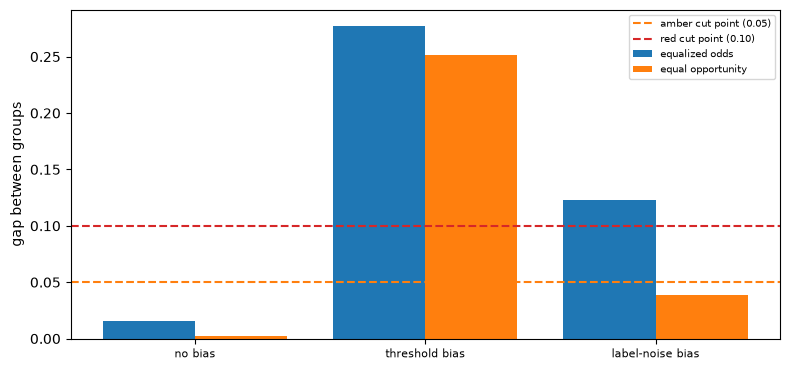

In [11]:
# Equalized-odds and equal-opportunity gaps of the three planted datasets against the lights' cut points
labels = list(draws)
equalized = [metrics.equalized_odds_difference(d["y"], d["decision"], d["group"]) for d in draws.values()]
opportunity = [
    metrics.equal_opportunity_difference(d["y"], d["decision"], d["group"]) for d in draws.values()
]
position = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(position - 0.2, equalized, width=0.4, label="equalized odds")
ax.bar(position + 0.2, opportunity, width=0.4, label="equal opportunity")
ax.axhline(0.05, color="tab:orange", linestyle="--", label="amber cut point (0.05)")
ax.axhline(0.10, color="tab:red", linestyle="--", label="red cut point (0.10)")
ax.set_xticks(position)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("gap between groups")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Without bias both gaps are near zero (0.0019 and 0.0157). With the threshold bias both jump far past the red line, to
0.2518 and 0.2775, and the selection rates differ (0.704 against 0.446). With label noise the equal-opportunity gap
is 0.0389, under the amber line, but the equalized-odds gap is 0.1229, over the red one, although the two groups are
approved at the same rate (0.704 and 0.702). The model is the same in both groups there, so the gap measures the
outcome, not the model.

### Step 6: the committed Taiwan battery

The Taiwan model of case C20 was screened for the same four outcome-based metrics across sex, marital status and age band. The twelve rows are labelled in the document as "labelled fairness evidence", with no four-fifths flag and no group-rate test. The next cell prints them with the light each gets from the engine's cut points (0.05 amber, 0.10 red, conventions), and rebuilds one of them from the committed group rates.

In [12]:
# Print the twelve committed rows of the Taiwan battery and rebuild one equalized-odds value
battery = taiwan["outputs"]["fairness_battery"]
print("label:", battery["label"], "| model:", battery["model"], "| test rows", len(battery["rows"]))
for r in battery["rows"]:
    print(
        f"{r['test_id']:32s} {r['attribute']:15s} value {r['value']:.4f} groups {len(r['groups'])}", end=" "
    )
    print(f"light {LIGHT[r['light']]}")
row = next(t for t in taiwan["tests"] if t["test_id"] == "fair.equalized_odds" and t["segment"] == "sex")
by_group = row["extras"]["rates_by_group"].values()
tpr_gap = max(g["tpr"] for g in by_group) - min(g["tpr"] for g in by_group)
fpr_gap = max(g["fpr"] for g in by_group) - min(g["fpr"] for g in by_group)
print("fair.equalized_odds / sex | committed", round(row["metric"], 6), end=" ")
print("| max(TPR, FPR) gaps from the group rates", round(max(tpr_gap, fpr_gap), 6))

label: labelled-fairness-battery | model: uci-taiwan | test rows 12
fair.equalized_odds              sex             value 0.0431 groups 2 light green
fair.equalized_odds              age             value 0.1083 groups 4 light red
fair.equalized_odds              marital_status  value 0.1127 groups 3 light red
fair.equal_opportunity           sex             value 0.0149 groups 2 light green
fair.equal_opportunity           age             value 0.1003 groups 4 light red
fair.equal_opportunity           marital_status  value 0.0325 groups 3 light green
fair.calibration_within_groups   sex             value 0.0877 groups 2 light amber
fair.calibration_within_groups   age             value 0.1047 groups 4 light red
fair.calibration_within_groups   marital_status  value 0.1565 groups 3 light red
fair.auc_by_group                sex             value 0.0120 groups 2 light green
fair.auc_by_group                age             value 0.0211 groups 4 light green
fair.auc_by_group            

## Results

**Answer:** Partly: the rates differ, but the data cannot say why, and most fairness measures cannot be computed on them. For Delaware 2018 the largest race gap is 0.2808 (amber); four of the five groups against the White group fall under the four-fifths line, the Black group at an adverse impact ratio of 0.7960 and an odds ratio of 0.4670 (z test p = 1.40e-128). HMDA holds no outcome, so equalized odds is refused there; on planted data its gap is 0.0157 without bias, 0.2775 with a threshold bias and 0.1229 with label noise, where the selection rates stay at 0.704 and 0.702.

- **The counts reproduce the committed rates exactly.** The race groups of Delaware 2018 have approval rates from 0.5108 (American Indian or Alaska Native, 139 applications) to 0.7755 (White, 24,293 applications), and every rate rebuilt by the engine equals the committed one. All four attributes (race, ethnicity, sex and age) give the same metric and the same light as the committed rows.
- **The parity gap and the four-fifths flag answer different questions.** For race the largest gap against the White group is 0.2808 (amber, a convention of 0.05) and four of the five other groups are flagged against the highest-rate group: the Black group has a ratio of 0.7960, below 0.8 by a hair, the American Indian group 0.6587. The Asian group (0.9840) is not flagged and its z test is compatible with chance (z = -1.068, p = 0.286). For ethnicity the gap is 0.0881 (amber) with a ratio of 0.8829 (green); for age the gap is 0.0933 (amber) and the lowest ratio 0.8082 (green); for sex the gap is 0.0019 (green).
- **A p-value is not a size.** The z test of the Black against the White group gives z = -24.124 and p = 1.40e-128, and the American Indian group z = -7.440 with p = 1.01e-13, from 139 applications. Both are red. The odds ratios (0.4670 and 0.3023) say how large, which the p-value does not. Fisher's exact p-values agree in sign and order of magnitude.
- **The legal frame bounds what the rates mean.** The document is labelled "no legal claim". It carries the sentence of Regulation B as amended (12 CFR 1002.6(a)) that the Act does not provide that the effects test applies, the Interagency Procedures sentence that gross HMDA rate disparities are not appropriate for disproportionate adverse impact analysis, and the flags that the unconditional rates are indicators only and a finding of violation is false. The four-fifths result carries `is_credit_law_threshold = False`, and the licence of the HMDA data is UNVERIFIED. None of the tests in this notebook decides discrimination.
- **The outcome-based metrics need an outcome and find what was planted.** The engine refuses to compute them on HMDA. On the plants: without bias the equal-opportunity gap is 0.0019 and the equalized-odds gap 0.0157; with the threshold bias the selection rates are 0.704 and 0.446 and the gaps 0.2518 and 0.2775. With label noise the selection rates are the same (0.704 and 0.702) because the model treats both groups alike, yet the equalized-odds gap is 0.1229, the protected group's calibration error is 0.0977 against 0.0093 and its AUC 0.6458 against 0.7671: the observed outcome, not the model, is what is wrong. A validator who finds those gaps has to ask first whether the outcome is measured alike in both groups.
- **The committed Taiwan battery gives a mixed picture.** Of the twelve rows, the equalized odds and equal opportunity gaps by age (0.1083 and 0.1003) and the equalized odds gap by marital status (0.1127) are red, the calibration within groups is red by age (0.1047) and marital status (0.1565) and amber by sex (0.0877), and the AUC by group is green for sex and age and amber for marital status (0.0568). The rows are labelled evidence with no four-fifths flag; the equalized odds value of sex is rebuilt from the group rates (0.043078) and equals the committed one. All rows were baked with riskvalidation 1.0.1.

What the results do not show: no test here establishes a cause, and gross rates of approval mix every difference between the groups' applications; the engine's lights are conventions (0.05 and 0.10, 5% and 1%) and the four-fifths rule is not a credit-law threshold; the plants are synthetic; and the Taiwan model is a research model, not a lender's.

## Summary

- Selection rates are computed on exact counts; parity, the adverse impact ratio and the four-fifths flag are decided on the integers, and the four-fifths rule is an employment benchmark used by analogy, never a credit-law threshold.
- A two-proportion z test and Fisher's exact test say whether a gap is compatible with chance; on thousands of applications they reject for small gaps, so the size of the gap and the odds ratio are read beside them.
- The committed HMDA comparison of Delaware 2018 is reproduced by the engine from its counts for race, ethnicity, sex and age; it is labelled "no legal claim", its rates are indicators only, and the licence of the data is UNVERIFIED.
- The outcome-based metrics (equal opportunity, equalized odds, calibration and AUC by group) need an outcome and refuse to run without one; a label-noise bias shows that a gap in them can come from the outcome and not from the model.
- The committed Taiwan battery has red rows by age and marital status, and every row is labelled evidence, not a finding of violation.

**What to try next.** Notebook 07 asks what remains of a disparity after the permitted controls, whether it repeats the next year, and what a situation test finds.

## References

- Hardt, M., Price, E. and Srebro, N. (2016), Equality of opportunity in supervised learning, arXiv 1610.02413. https://arxiv.org/abs/1610.02413
- 29 CFR 1607.4(D), Uniform Guidelines on Employee Selection Procedures: the four-fifths rule, an employment benchmark. https://www.law.cornell.edu/cfr/text/29/1607.4
- CFPB (2026), Equal Credit Opportunity Act (Regulation B), final rule, 91 FR 21620, effective 2026-07-21. https://www.govinfo.gov/content/pkg/FR-2026-04-22/pdf/2026-07804.pdf
- OCC, FDIC, Federal Reserve Board, OTS and NCUA (2009), Interagency Fair Lending Examination Procedures. https://www.federalreserve.gov/boarddocs/caletters/2009/0906/09-06_attachment.pdf
- Kozodoi, N., Jacob, J. and Lessmann, S. (2022), Fairness in credit scoring: assessment, implementation and profit implications, European Journal of Operational Research 297(3). https://doi.org/10.1016/j.ejor.2021.06.023
- FFIEC and CFPB, Home Mortgage Disclosure Act data publication (the licence sentence of the data is UNVERIFIED). https://ffiec.cfpb.gov/data-publication/
- Yeh, I-C. and Lien, C-H., Default of credit card clients, UCI Machine Learning Repository (CC BY 4.0), the Taiwan cards of the C20 variants. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients